# DATA 400 Mini Project
## Predicting 5-Year Charge-Off Risk for SBA 7(a) Loans

**Final notebook status:** This submission version synchronizes the code, saved real-data outputs, and written interpretations. The SBA source is the June 30, 2026 snapshot, and the predictive sample is restricted to loans with a complete five-year outcome window.


**Research question:**  
Using information available around loan approval, how well can we predict whether an SBA 7(a) loan will be charged off within five years?

**Target:** `chargeoff_5yr`

- `1` = documented charge-off within 5 years after approval
- `0` = no documented charge-off within the first 5 years
- loans without a complete 5-year observation window are not used in the prediction model

The main modeling sample ends at **June 30, 2021** because the SBA data snapshot is June 30, 2026.

The notebook follows the same general style as the earlier consumer-credit project:

1. understand the data
2. check missing values and unusual values
3. create useful variables
4. split the data
5. explore patterns
6. train several classification models
7. evaluate precision, recall, F1, PR-AUC, ROC-AUC, and confusion matrix
8. choose a threshold using validation data
9. check overfitting/generalization
10. inspect model errors
11. evaluate the final model once on the locked test set


## Step 0 — Setup

The official SBA files are large, so I save them in a project folder instead of downloading them every time.

If this is running in Google Colab, the code will mount Google Drive.  
If it is running locally, it will use the current folder.


In [1]:
import sys
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Use Google Drive when running in Colab
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/DATA400_SBA_Credit_Risk")
else:
    PROJECT_DIR = Path.cwd() / "DATA400_SBA_Credit_Risk"

RAW_DIR = PROJECT_DIR / "data" / "raw"
OUTPUT_DIR = PROJECT_DIR / "output"
FIGURE_DIR = PROJECT_DIR / "figures"

for folder in [RAW_DIR, OUTPUT_DIR, FIGURE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_DIR)

Project folder: /Users/chloepham/Downloads/DATA400_SBA_Credit_Risk


## Step 1 — Download the real SBA data

Source: **U.S. Small Business Administration, 7(a) & 504 FOIA dataset**

Official page:  
https://data.sba.gov/dataset/7a-504-foia

The source is split into FY2010–FY2019 and FY2020–Present files. I load both because the second file contains the 2020 through June 2021 loans that can still have a complete five-year observation window as of June 30, 2026.

**Important:** loans approved after the five-year maturity cutoff are removed before modeling. They are not used in a separate recent-loan analysis in this version, so the mini-project stays focused on the predictive question.


In [2]:
import requests
from tqdm.auto import tqdm

SOURCE_PAGE = "https://data.sba.gov/dataset/7a-504-foia"

URL_2010_2019 = (
    "https://data.sba.gov/sites/default/files/uploaded_resources/"
    "FOIA_7a_FY2010_FY2019_asof_260630.csv"
)

URL_2020_PRESENT = (
    "https://data.sba.gov/sites/default/files/uploaded_resources/"
    "FOIA_7a_FY2020_Present_asof_260630.csv"
)

DATA_DICTIONARY_URL = (
    "https://data.sba.gov/sites/default/files/uploaded_resources/"
    "7a_504_foia_data_dictionary.xlsx"
)

FILE_2010_2019 = RAW_DIR / "FOIA_7a_FY2010_FY2019_asof_260630.csv"
FILE_2020_PRESENT = RAW_DIR / "FOIA_7a_FY2020_Present_asof_260630.csv"
DICT_FILE = RAW_DIR / "7a_504_foia_data_dictionary.xlsx"


def download_file(url, destination):
    """Download only if the file is not already in the project folder."""
    destination = Path(destination)

    if destination.exists():
        print(f"Already downloaded: {destination.name}")
        return

    print(f"Downloading {destination.name} ...")
    response = requests.get(url, stream=True, timeout=120)
    response.raise_for_status()

    total = int(response.headers.get("content-length", 0))
    with open(destination, "wb") as f, tqdm(
        total=total,
        unit="B",
        unit_scale=True,
        desc=destination.name
    ) as pbar:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if chunk:
                f.write(chunk)
                pbar.update(len(chunk))

    print("Saved to:", destination)


download_file(URL_2010_2019, FILE_2010_2019)
download_file(URL_2020_PRESENT, FILE_2020_PRESENT)
download_file(DATA_DICTIONARY_URL, DICT_FILE)

FOIA_7a_FY2010_FY2019_asof_260630.csv: 100%|██████████| 255M/255M [00:49<00:00, 5.14MB/s] 


Saved to: /Users/chloepham/Downloads/DATA400_SBA_Credit_Risk/data/raw/FOIA_7a_FY2010_FY2019_asof_260630.csv


FOIA_7a_FY2020_Present_asof_260630.csv: 100%|██████████| 181M/181M [00:26<00:00, 6.75MB/s] 


Saved to: /Users/chloepham/Downloads/DATA400_SBA_Credit_Risk/data/raw/FOIA_7a_FY2020_Present_asof_260630.csv


7a_504_foia_data_dictionary.xlsx: 100%|██████████| 24.5k/24.5k [00:00<00:00, 52.9MB/s]

Saved to: /Users/chloepham/Downloads/DATA400_SBA_Credit_Risk/data/raw/7a_504_foia_data_dictionary.xlsx


### 1A. Read only the columns we need

The raw files contain borrower names, addresses, lender addresses, and other fields that are not needed for this question.

I intentionally do **not** use borrower name or street address as predictors. The model should focus on interpretable loan and business characteristics.

The helper below also handles small changes in column names between SBA file versions.


In [3]:
def normalize_col_name(name):
    """Lowercase and remove spaces / punctuation so names are easier to match."""
    return re.sub(r"[^a-z0-9]", "", str(name).lower())


FIELD_ALIASES = {
    "as_of_date": ["asofdate"],
    "approval_date": ["approvaldate"],
    "approval_fy": ["approvalfy", "approvalfiscalyear"],

    "gross_approval": ["grossapproval"],
    "sba_guaranteed_approval": ["sbaguaranteedapproval"],
    "initial_interest_rate": ["initialinterestrate"],
    "term_months": ["terminmonths"],

    "naics_code": ["naicscode"],
    "project_state": ["projectstate"],
    "business_type": ["businesstype"],
    "business_age": ["businessage"],
    "processing_method": ["processingmethod"],
    "subprogram": ["subprogram", "subpgmdesc"],

    "fixed_variable": [
        "fixedorvariableinterestind",
        "fixedorvariableinterestrate",
        "fixedorvariable"
    ],
    "revolver_status": ["revolverstatus"],
    "collateral_ind": ["collateralind", "collateralindicator"],
    "jobs_supported": ["jobssupported"],
    "franchise_code": ["franchisecode"],

    # Outcome fields. These are used only to construct/check the target.
    "loan_status": ["loanstatus"],
    "chargeoff_date": ["chargeoffdate"],
    "gross_chargeoff_amount": [
        "grosschargeoffamount",
        "grosschargeoffamt"
    ],
    "paid_in_full_date": ["paidinfulldate"],
}


CRITICAL_FIELDS = [
    "as_of_date",
    "approval_date",
    "gross_approval",
    "term_months",
    "loan_status",
    "chargeoff_date"
]


def get_column_map(csv_path):
    """Map the raw SBA column names to consistent notebook names."""
    raw_columns = pd.read_csv(csv_path, nrows=0).columns.tolist()
    normalized_to_raw = {normalize_col_name(c): c for c in raw_columns}

    mapping = {}
    for standard_name, aliases in FIELD_ALIASES.items():
        for alias in aliases:
            if alias in normalized_to_raw:
                mapping[standard_name] = normalized_to_raw[alias]
                break

    return mapping, raw_columns


def read_sba_file(csv_path):
    mapping, raw_columns = get_column_map(csv_path)

    print(f"\nReading: {Path(csv_path).name}")
    print(f"Columns in raw file: {len(raw_columns)}")
    print(f"Columns selected: {len(mapping)}")

    missing_expected = [
        name for name in FIELD_ALIASES
        if name not in mapping
    ]

    if missing_expected:
        print("Optional/expected fields not found:", missing_expected)

    missing_critical = [c for c in CRITICAL_FIELDS if c not in mapping]
    if missing_critical:
        raise ValueError(
            "The SBA file is missing critical fields needed for this project: "
            + ", ".join(missing_critical)
        )

    usecols = list(mapping.values())

    temp = pd.read_csv(
        csv_path,
        usecols=usecols,
        low_memory=False
    )

    raw_to_standard = {raw: std for std, raw in mapping.items()}
    temp = temp.rename(columns=raw_to_standard)

    return temp


df_2010_2019 = read_sba_file(FILE_2010_2019)
df_2020_present = read_sba_file(FILE_2020_PRESENT)

df_raw = pd.concat(
    [df_2010_2019, df_2020_present],
    ignore_index=True,
    sort=False
)

# The public files can contain exact duplicate records.
before_dupes = len(df_raw)
df_raw = df_raw.drop_duplicates().reset_index(drop=True)
duplicates_removed = before_dupes - len(df_raw)

print("\nCombined shape after exact-duplicate removal:", df_raw.shape)
print("Exact duplicate rows removed:", duplicates_removed)
print("Selected columns:", sorted(df_raw.columns.tolist()))



Reading: FOIA_7a_FY2010_FY2019_asof_260630.csv
Columns in raw file: 42
Columns selected: 21
Optional/expected fields not found: ['subprogram']

Reading: FOIA_7a_FY2020_Present_asof_260630.csv
Columns in raw file: 42
Columns selected: 21
Optional/expected fields not found: ['subprogram']

Combined shape after exact-duplicate removal: (932013, 21)
Exact duplicate rows removed: 2076
Selected columns: ['approval_date', 'approval_fy', 'as_of_date', 'business_age', 'business_type', 'chargeoff_date', 'collateral_ind', 'fixed_variable', 'franchise_code', 'gross_approval', 'gross_chargeoff_amount', 'initial_interest_rate', 'jobs_supported', 'loan_status', 'naics_code', 'paid_in_full_date', 'processing_method', 'project_state', 'revolver_status', 'sba_guaranteed_approval', 'term_months']


## Step 2 — First look at the data

This is the same idea as the beginning of my consumer-credit notebook: start simple before modeling.

I want to know:

- how many rows and columns there are
- data types
- missing values
- ranges of numerical variables
- what the status values look like

I am **not** using the test set for EDA yet. This is only a basic data-quality check needed to construct the outcome and time split.


In [4]:
pd.set_option("display.max_columns", None)

print("Shape:", df_raw.shape)
display(df_raw.head())

print("\nData types:")
display(df_raw.dtypes.to_frame("dtype"))

print("\nMissing values:")
missing_raw = (
    df_raw.isna().mean()
    .sort_values(ascending=False)
    .rename("missing_rate")
    .to_frame()
)
display(missing_raw)

if "loan_status" in df_raw.columns:
    print("\nLoan status values:")
    display(df_raw["loan_status"].value_counts(dropna=False).head(20))

Shape: (932013, 21)


,as_of_date,gross_approval,sba_guaranteed_approval,approval_date,approval_fy,processing_method,initial_interest_rate,fixed_variable,term_months,naics_code,franchise_code,project_state,business_type,business_age,loan_status,paid_in_full_date,chargeoff_date,gross_chargeoff_amount,revolver_status,jobs_supported,collateral_ind
0,2026-06-30,288000.0,259200.0,2009-10-01,2010,Preferred Lenders Program,6.00,V,120.0,722110.0,NaN,TX,CORPORATION,Unanswered,P I F,2014-07-31,NaN,0.0,N,18.0,Y
1,2026-06-30,1200000.0,1080000.0,2009-10-01,2010,Preferred Lenders Program,4.75,V,300.0,541940.0,NaN,FL,PARTNERSHIP,"Existing, 5 or more years",P I F,2017-02-28,NaN,0.0,N,10.0,N
2,2026-06-30,120000.0,108000.0,2009-10-01,2010,Preferred Lenders Program,5.25,V,90.0,312113.0,NaN,TX,CORPORATION,Less than 4 years old but at least 3,P I F,2012-05-31,NaN,0.0,N,4.0,N
3,2026-06-30,150000.0,75000.0,2009-10-01,2010,SBA Express Program,5.25,V,60.0,722211.0,48400,MI,CORPORATION,"Startup, Loan Funds will Open Business",P I F,2014-12-31,NaN,0.0,N,48.0,Y
4,2026-06-30,790000.0,711000.0,2009-10-01,2010,Preferred Lenders Program,6.00,V,240.0,447110.0,NaN,IL,CORPORATION,"New, Less than 1 Year old",CANCLD,NaN,NaN,0.0,N,0.0,Y



Data types:


,dtype
as_of_date,object
gross_approval,float64
sba_guaranteed_approval,float64
approval_date,object
approval_fy,int64
processing_method,object
initial_interest_rate,float64
fixed_variable,object
term_months,float64
naics_code,float64



Missing values:


,missing_rate
chargeoff_date,0.955976
franchise_code,0.899204
paid_in_full_date,0.503859
business_age,0.002157
business_type,0.000062
initial_interest_rate,0.000009
fixed_variable,0.000009
jobs_supported,0.000002
naics_code,0.000002
revolver_status,0.000000



Loan status values:


loan_status
P I F     462409
EXEMPT    291921
CANCLD    115531
CHGOFF     41046
COMMIT     21106
Name: count, dtype: int64

## Step 3 — Clean fields and construct the 5-year target

The key issue is **right censoring**. A recent loan cannot be called a five-year non-charge-off simply because five years have not passed.

For each loan:

**Five-year maturity date = approval date + 5 years**

A loan enters the modeling sample only if that five-year date is on or before the SBA snapshot date.

### Leakage rule

`LoanStatus`, `ChargeOffDate`, `GrossChargeOffAmount`, and `PaidInFullDate` are outcome information. They may be used to construct or validate the target, but they are never used as predictors.


In [5]:
def parse_mixed_date(series):
    """
    SBA dates can appear as YYYYMMDD or normal date strings.
    This parser handles both.
    """
    s = (
        series.astype("string")
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
    )

    out = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")

    yyyymmdd = s.str.fullmatch(r"\d{8}", na=False)

    out.loc[yyyymmdd] = pd.to_datetime(
        s.loc[yyyymmdd],
        format="%Y%m%d",
        errors="coerce"
    )

    # Avoid relying only on format="mixed" so the notebook is more portable.
    out.loc[~yyyymmdd] = pd.to_datetime(
        s.loc[~yyyymmdd],
        errors="coerce"
    )

    return out


def to_number(series):
    """Convert amounts/rates to numeric even if commas or dollar signs appear."""
    return pd.to_numeric(
        series.astype("string").str.replace(r"[$,% ,]", "", regex=True),
        errors="coerce"
    )


df = df_raw.copy()

# Dates
for col in ["as_of_date", "approval_date", "chargeoff_date", "paid_in_full_date"]:
    if col in df.columns:
        df[col] = parse_mixed_date(df[col])

# Numeric fields
for col in [
    "gross_approval",
    "sba_guaranteed_approval",
    "initial_interest_rate",
    "term_months",
    "jobs_supported",
    "gross_chargeoff_amount",
    "approval_fy",
]:
    if col in df.columns:
        df[col] = to_number(df[col])

# Standardize status codes.
# Example: "P I F" -> "PIF", "PURCH(NOT C/O)" -> "PURCHNOTCO".
df["loan_status_clean"] = (
    df["loan_status"]
    .astype("string")
    .str.upper()
    .str.replace(r"[^A-Z0-9]", "", regex=True)
)

# Find the snapshot date from the source rows.
snapshot_date = df["as_of_date"].dropna().max()

if pd.isna(snapshot_date):
    snapshot_date = pd.Timestamp("2026-06-30")

print("SBA snapshot date:", snapshot_date.date())

# Latest approval date that can have five complete years of follow-up
maturity_cutoff = snapshot_date - pd.DateOffset(years=5)
print("Latest approval date allowed in the 5-year model:", maturity_cutoff.date())

# A loan can be assigned a five-year outcome only after five full years have passed.
df["five_year_date"] = df["approval_date"] + pd.DateOffset(years=5)
df["has_full_5yr_window"] = df["five_year_date"] <= snapshot_date

# These are approvals that did not become an observable funded-loan performance record.
nonfunded_statuses = {"CANCLD", "COMMIT", "NOTFUNDED"}
df["eligible_status"] = ~df["loan_status_clean"].isin(nonfunded_statuses)

# SBA status vocabulary has changed across quarterly releases.
# CHGOFF = charged off.
# CLSLN / SOLDCO have also been used for post-charge-off outcomes.
chargeoff_status = df["loan_status_clean"].str.contains(
    r"CHGOFF|CLSLN|SOLDCO",
    regex=True,
    na=False
)

gross_co = (
    df["gross_chargeoff_amount"].fillna(0)
    if "gross_chargeoff_amount" in df.columns
    else pd.Series(0, index=df.index)
)

df["has_chargeoff_evidence"] = (
    df["chargeoff_date"].notna()
    | (gross_co > 0)
    | chargeoff_status
)

# If the file says a loan was charged off but gives no date,
# we cannot know whether it happened within exactly five years.
df["ambiguous_chargeoff_timing"] = (
    df["has_chargeoff_evidence"]
    & df["chargeoff_date"].isna()
)

# Exact five-year target:
# 1 only when a documented charge-off occurred within five years after approval.
df["chargeoff_5yr"] = np.where(
    df["chargeoff_date"].notna()
    & (df["chargeoff_date"] >= df["approval_date"])
    & (df["chargeoff_date"] <= df["five_year_date"]),
    1,
    0
)

model_df = df[
    df["approval_date"].notna()
    & df["has_full_5yr_window"]
    & df["eligible_status"]
    & ~df["ambiguous_chargeoff_timing"]
].copy()

print("All raw loans after duplicate removal:", len(df))
print("Loans with full 5-year window and usable target:", len(model_df))
print("Loans excluded because charge-off timing was ambiguous:",
      int(df["ambiguous_chargeoff_timing"].sum()))

if len(model_df):
    print("Latest approval date eligible for 5-year target:",
          model_df["approval_date"].max().date())

print("\nTarget count:")
display(model_df["chargeoff_5yr"].value_counts(dropna=False).rename("count").to_frame())

print("\nTarget rate:")
print(f"{model_df['chargeoff_5yr'].mean():.2%}")

print("\nMost common normalized statuses in the modeling universe:")
display(
    model_df["loan_status_clean"]
    .value_counts(dropna=False)
    .head(15)
    .rename("count")
    .to_frame()
)


SBA snapshot date: 2026-06-30
Latest approval date allowed in the 5-year model: 2021-06-30
All raw loans after duplicate removal: 932013
Loans with full 5-year window and usable target: 543110
Loans excluded because charge-off timing was ambiguous: 15
Latest approval date eligible for 5-year target: 2021-06-30

Target count:


,count
chargeoff_5yr,
0,522667
1,20443



Target rate:
3.76%

Most common normalized statuses in the modeling universe:


,count
loan_status_clean,
PIF,429221
EXEMPT,77487
CHGOFF,36402


## Step 4 — Time split before target-based EDA

The sample has already been restricted to loans with a complete five-year outcome window. I then split the loans chronologically by approval date:

- **Training:** October 1, 2009 through December 31, 2017
- **Validation / model selection:** January 1, 2018 through December 31, 2019
- **Locked test:** January 1, 2020 through June 30, 2021

The training data begin in October 2009 because the SBA FY2010 source includes approvals beginning at the start of federal fiscal year 2010.

This is intentionally not a random split. The question is whether a model learned from older loan cohorts generalizes to later cohorts. The test set remains untouched until the model and threshold choices are finished.


In [6]:
TRAIN_END = pd.Timestamp("2017-12-31")
VAL_START = pd.Timestamp("2018-01-01")
VAL_END = pd.Timestamp("2019-12-31")
TEST_START = pd.Timestamp("2020-01-01")

# model_df is already restricted to approval_date <= maturity_cutoff
train_df = model_df[
    model_df["approval_date"] <= TRAIN_END
].copy()

val_df = model_df[
    (model_df["approval_date"] >= VAL_START)
    & (model_df["approval_date"] <= VAL_END)
].copy()

test_df = model_df[
    (model_df["approval_date"] >= TEST_START)
    & (model_df["approval_date"] <= maturity_cutoff)
].copy()

split_summary = pd.DataFrame({
    "rows": [len(train_df), len(val_df), len(test_df)],
    "chargeoff_rate": [
        train_df["chargeoff_5yr"].mean(),
        val_df["chargeoff_5yr"].mean(),
        test_df["chargeoff_5yr"].mean()
    ],
    "start_date": [
        train_df["approval_date"].min(),
        val_df["approval_date"].min(),
        test_df["approval_date"].min()
    ],
    "end_date": [
        train_df["approval_date"].max(),
        val_df["approval_date"].max(),
        test_df["approval_date"].max()
    ]
}, index=["Train", "Validation", "Test"])

display(split_summary)

assert len(train_df) > 0, "Training set is empty."
assert len(val_df) > 0, "Validation set is empty."
assert len(test_df) > 0, "Test set is empty."
assert test_df["approval_date"].max() <= maturity_cutoff

print("\nFive-year maturity cutoff:", maturity_cutoff.date())
print("The test set is now locked. Do not use it for model choices.")


,rows,chargeoff_rate,start_date,end_date
Train,393008,0.038556,2009-10-01,2017-12-31
Validation,95853,0.041835,2018-01-01,2019-12-31
Test,54249,0.023595,2020-01-01,2021-06-30



Five-year maturity cutoff: 2021-06-30
The test set is now locked. Do not use it for model choices.


# EDA — training data only

From here until the final test section, all outcome-based exploration uses the **training set**.

This follows the lecture idea that the test data should not influence feature choices or model choices.


## Step 5 — Missing values and basic distributions


In [7]:
print("Training target distribution:")
target_table = train_df["chargeoff_5yr"].value_counts().sort_index()
display(target_table.rename("count").to_frame())

print(f"Training charge-off rate: {train_df['chargeoff_5yr'].mean():.2%}")

missing_train = (
    train_df.isna().mean()
    .sort_values(ascending=False)
    .rename("missing_rate")
    .to_frame()
)

print("\nTop missing-value rates in training data:")
display(missing_train.head(20))

Training target distribution:


,count
chargeoff_5yr,
0,377855
1,15153


Training charge-off rate: 3.86%

Top missing-value rates in training data:


,missing_rate
chargeoff_date,0.928923
franchise_code,0.919890
paid_in_full_date,0.139323
business_age,0.002036
business_type,0.000046
naics_code,0.000005
revolver_status,0.000000
jobs_supported,0.000000
as_of_date,0.000000
gross_chargeoff_amount,0.000000


## Step 6 — Create simple credit-risk bands for EDA

My earlier consumer-credit notebook created FICO, DTI, utilization, loan amount, and asset bands.

This SBA dataset does not have FICO or borrower income, so the useful bands are different:

- loan amount
- loan term
- interest rate
- SBA guarantee percentage
- industry


In [8]:
def add_features(data):
    out = data.copy()

    # Create any optional columns that are absent in a particular SBA extract.
    optional_defaults = {
        "sba_guaranteed_approval": np.nan,
        "initial_interest_rate": np.nan,
        "jobs_supported": np.nan,
        "naics_code": pd.NA,
        "franchise_code": pd.NA,
    }

    for col, default in optional_defaults.items():
        if col not in out.columns:
            out[col] = default

    # Main numeric fields
    for col in [
        "gross_approval",
        "sba_guaranteed_approval",
        "initial_interest_rate",
        "term_months",
        "jobs_supported",
    ]:
        out[col] = to_number(out[col])

    # Ratio: percentage of gross approval guaranteed by SBA
    out["guarantee_pct"] = (
        out["sba_guaranteed_approval"]
        / out["gross_approval"].replace(0, np.nan)
    )

    # Loan dollars are right-skewed
    out["log_gross_approval"] = np.log1p(
        out["gross_approval"].clip(lower=0)
    )

    out["approval_year"] = out["approval_date"].dt.year

    # Broad 2-digit NAICS sector
    naics = (
        out["naics_code"]
        .astype("string")
        .str.replace(r"\.0$", "", regex=True)
        .str.strip()
    )
    out["naics2"] = naics.str[:2]
    out.loc[
        ~out["naics2"].str.fullmatch(r"\d{2}", na=False),
        "naics2"
    ] = "Unknown"

    # Simple franchise indicator
    franchise = out["franchise_code"].astype("string").str.strip()
    out["is_franchise"] = np.where(
        franchise.notna()
        & ~franchise.isin(["", "0", "nan", "<NA>"]),
        "Yes",
        "No"
    )

    # EDA-only bands
    out["loan_amount_band"] = pd.cut(
        out["gross_approval"],
        bins=[0, 50_000, 150_000, 500_000, 1_000_000, np.inf],
        labels=[
            "<$50K",
            "$50K-$150K",
            "$150K-$500K",
            "$500K-$1M",
            "$1M+"
        ],
        include_lowest=True
    )

    out["term_band"] = pd.cut(
        out["term_months"],
        bins=[0, 84, 120, 180, np.inf],
        labels=["<=84 mo", "85-120 mo", "121-180 mo", ">180 mo"],
        include_lowest=True
    )

    out["interest_rate_band"] = pd.cut(
        out["initial_interest_rate"],
        bins=[0, 5, 8, 11, np.inf],
        labels=["<5%", "5-8%", "8-11%", "11%+"],
        include_lowest=True
    )

    out["guarantee_band"] = pd.cut(
        out["guarantee_pct"],
        bins=[0, 0.50, 0.75, 0.85, np.inf],
        labels=["<=50%", "50-75%", "75-85%", ">85%"],
        include_lowest=True
    )

    return out

# Create feature-enhanced copies for training EDA and validation modeling.
train_eda = add_features(train_df)
val_model = add_features(val_df)

# The test set stays locked until the final evaluation section.


In [9]:
def rate_table(data, group_col, min_count=100):
    table = (
        data.groupby(group_col, observed=False)["chargeoff_5yr"]
        .agg(["count", "mean"])
        .rename(columns={"mean": "chargeoff_rate"})
    )
    return table[table["count"] >= min_count].sort_values(
        "chargeoff_rate",
        ascending=False
    )


print("Charge-off rate by loan amount band:")
display(rate_table(train_eda, "loan_amount_band", min_count=100))

print("\nCharge-off rate by loan term band:")
display(rate_table(train_eda, "term_band", min_count=100))

print("\nCharge-off rate by interest-rate band:")
display(rate_table(train_eda, "interest_rate_band", min_count=100))

print("\nCharge-off rate by SBA guarantee band:")
display(rate_table(train_eda, "guarantee_band", min_count=100))

print("\nCharge-off rate by broad NAICS sector:")
display(rate_table(train_eda, "naics2", min_count=500).head(15))

Charge-off rate by loan amount band:


,count,chargeoff_rate
loan_amount_band,,
<$50K,135960,0.055855
$50K-$150K,91372,0.044937
$150K-$500K,90933,0.028988
$500K-$1M,36722,0.013425
$1M+,38021,0.008522



Charge-off rate by loan term band:


,count,chargeoff_rate
term_band,,
<=84 mo,219812,0.051121
85-120 mo,85767,0.040388
121-180 mo,21537,0.006361
>180 mo,65892,0.004781



Charge-off rate by interest-rate band:


,count,chargeoff_rate
interest_rate_band,,
8-11%,48910,0.073032
5-8%,282854,0.038013
<5%,61241,0.013537



Charge-off rate by SBA guarantee band:


,count,chargeoff_rate
guarantee_band,,
75-85%,46098,0.073756
<=50%,192700,0.041111
>85%,27701,0.040287
50-75%,126509,0.021461



Charge-off rate by broad NAICS sector:


,count,chargeoff_rate
naics2,,
45,14918,0.056576
48,18105,0.055786
42,21367,0.046146
71,10813,0.045778
72,50426,0.042399
23,40148,0.041895
44,39923,0.041530
49,1296,0.040895
51,4816,0.040698


## Step 7 — EDA plots

For every plot in the final report/presentation, write:

1. one sentence saying what pattern you see  
2. one sentence saying why that pattern matters or what its limitation is


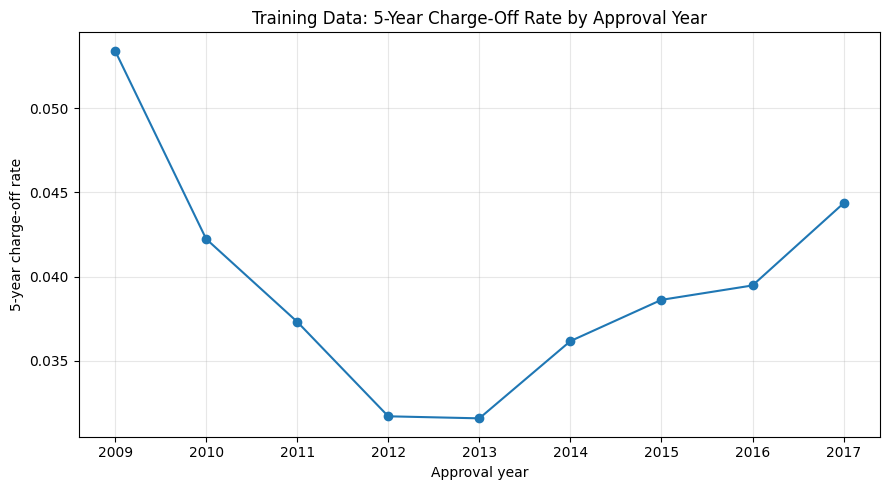

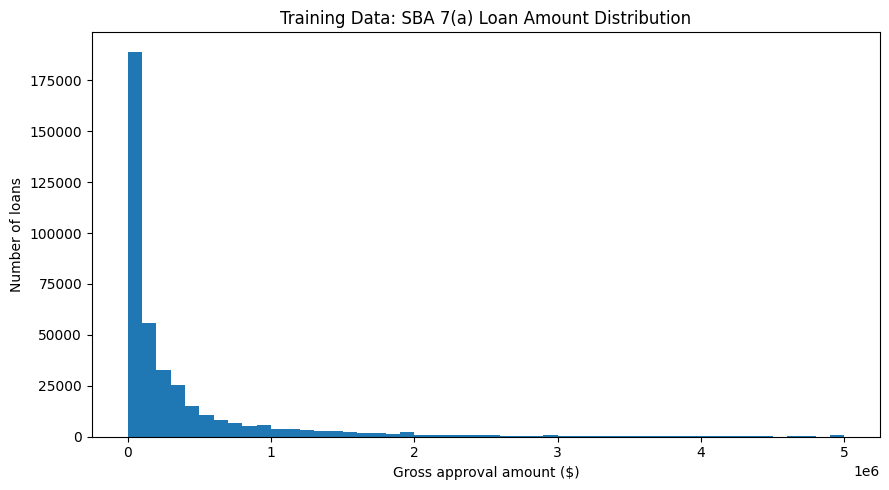

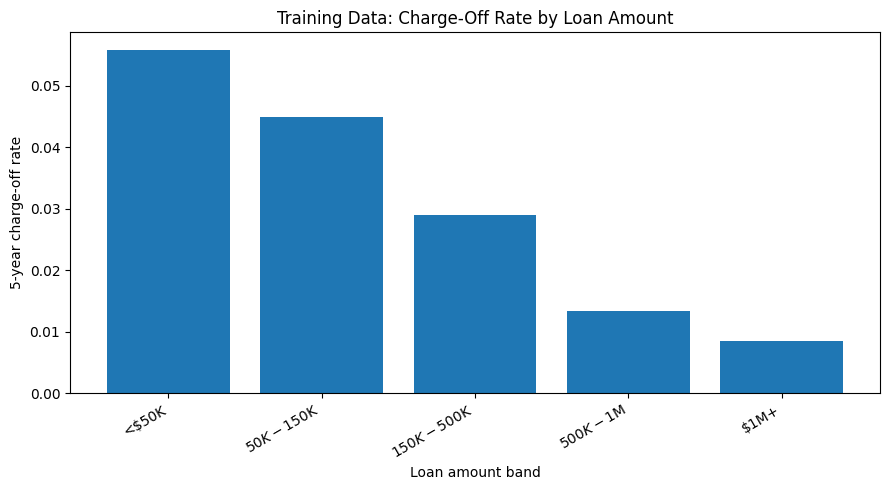

In [10]:
# 1. Charge-off rate by approval year
year_rate = (
    train_eda.groupby("approval_year")["chargeoff_5yr"]
    .mean()
    .sort_index()
)

plt.figure(figsize=(9, 5))
plt.plot(year_rate.index, year_rate.values, marker="o")
plt.xlabel("Approval year")
plt.ylabel("5-year charge-off rate")
plt.title("Training Data: 5-Year Charge-Off Rate by Approval Year")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "chargeoff_rate_by_year.png", dpi=160)
plt.show()


# 2. Loan amount distribution
plt.figure(figsize=(9, 5))
valid_amount = train_eda["gross_approval"].dropna()
plt.hist(valid_amount, bins=50)
plt.xlabel("Gross approval amount ($)")
plt.ylabel("Number of loans")
plt.title("Training Data: SBA 7(a) Loan Amount Distribution")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "loan_amount_distribution.png", dpi=160)
plt.show()


# 3. Charge-off rate by loan amount band
amount_rate = (
    train_eda.groupby("loan_amount_band", observed=False)["chargeoff_5yr"]
    .mean()
)

plt.figure(figsize=(9, 5))
plt.bar(amount_rate.index.astype(str), amount_rate.values)
plt.xlabel("Loan amount band")
plt.ylabel("5-year charge-off rate")
plt.title("Training Data: Charge-Off Rate by Loan Amount")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "chargeoff_by_loan_amount_band.png", dpi=160)
plt.show()

## Step 8 — Correlation with the target

This is similar to the correlation section in my earlier credit notebook.

For a binary target, the normal Pearson correlation is still useful as a quick descriptive check for numerical variables. It does **not** prove causation.


,correlation_with_chargeoff_5yr
term_months,-0.134878
gross_approval,-0.064920
sba_guaranteed_approval,-0.063126
jobs_supported,-0.026835
approval_year,0.003412
guarantee_pct,0.004259
initial_interest_rate,0.104092


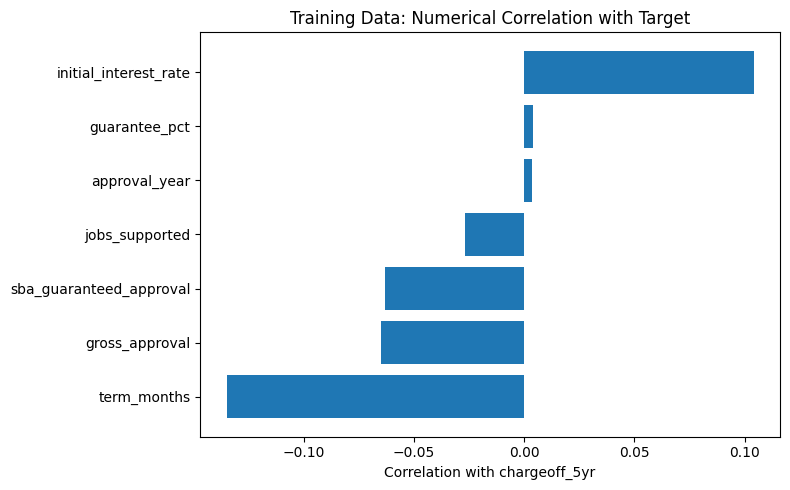

In [11]:
numeric_for_corr = [
    "gross_approval",
    "sba_guaranteed_approval",
    "guarantee_pct",
    "initial_interest_rate",
    "term_months",
    "jobs_supported",
    "approval_year",
    "chargeoff_5yr"
]

corr_data = train_eda[
    [c for c in numeric_for_corr if c in train_eda.columns]
].copy()

corr_with_target = (
    corr_data.corr(numeric_only=True)["chargeoff_5yr"]
    .drop("chargeoff_5yr")
    .sort_values()
)

display(corr_with_target.to_frame("correlation_with_chargeoff_5yr"))

plt.figure(figsize=(8, 5))
plt.barh(corr_with_target.index, corr_with_target.values)
plt.xlabel("Correlation with chargeoff_5yr")
plt.title("Training Data: Numerical Correlation with Target")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "numeric_target_correlations.png", dpi=160)
plt.show()

## Step 9 — Outlier check

The previous consumer-credit notebook used the 1.5×IQR method and automatically removed outliers.

For this SBA project I still **check** IQR outliers, but I do not automatically delete them.

A \$3 million loan may be statistically unusual, but it can still be a real SBA loan. Automatically removing every large value could remove exactly the loans we want to understand.

Instead, I:

- flag unusual values
- check for impossible values
- use a log transformation for highly skewed loan amounts


In [12]:
def iqr_outlier_summary(data, columns):
    rows = []

    for col in columns:
        s = pd.to_numeric(data[col], errors="coerce").dropna()

        if len(s) == 0:
            continue

        q1 = s.quantile(0.25)
        q3 = s.quantile(0.75)
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        count = ((s < lower) | (s > upper)).sum()

        rows.append({
            "variable": col,
            "q1": q1,
            "q3": q3,
            "lower_iqr_bound": lower,
            "upper_iqr_bound": upper,
            "flagged_rows": int(count),
            "flagged_pct": count / len(s)
        })

    return pd.DataFrame(rows)


outlier_summary = iqr_outlier_summary(
    train_eda,
    [
        "gross_approval",
        "initial_interest_rate",
        "term_months",
        "jobs_supported",
        "guarantee_pct"
    ]
)

display(outlier_summary)

# Basic impossible-value checks
quality_checks = {
    "gross_approval <= 0": (
        train_eda["gross_approval"].fillna(1) <= 0
    ).sum(),

    "term_months <= 0": (
        train_eda["term_months"].fillna(1) <= 0
    ).sum(),

    "interest_rate < 0": (
        train_eda["initial_interest_rate"].fillna(0) < 0
    ).sum(),

    "guarantee_pct > 1.05": (
        train_eda["guarantee_pct"].fillna(0) > 1.05
    ).sum()
}

display(pd.Series(quality_checks, name="rows").to_frame())

,variable,q1,q3,lower_iqr_bound,upper_iqr_bound,flagged_rows,flagged_pct
0,gross_approval,40000.00,350000.00,-425000.000,815000.000,48355,0.123038
1,initial_interest_rate,5.49,7.00,3.225,9.265,23988,0.061037
2,term_months,83.00,120.00,27.500,175.500,90235,0.229601
3,jobs_supported,2.00,12.00,-13.000,27.000,36709,0.093405
4,guarantee_pct,0.50,0.75,0.125,1.125,0,0.000000


,rows
gross_approval <= 0,0
term_months <= 0,208
interest_rate < 0,0
guarantee_pct > 1.05,0


### Data-quality interpretation

The quality check found **208 training observations with `term_months <= 0`**. This is about **0.05% of the 393,008 training loans**.

I flag these observations as a data-quality limitation rather than automatically deleting them after model development. The check found no non-positive gross approval amounts, no negative interest rates, and no SBA guarantee percentages above 1.05.

The IQR table also flags many statistically unusual observations, but I do not automatically remove them because large loans, long terms, or unusual job counts can still be legitimate SBA records.

# Modeling

## Step 10 — Choose predictors

Only variables that are reasonably available around approval are used.

### Numerical predictors
- log loan amount
- SBA guarantee percentage
- loan term
- initial interest rate
- jobs supported
- approval year

### Categorical predictors
- project state
- business type
- business age
- processing method
- fixed/variable rate
- revolving status
- collateral indicator
- broad NAICS sector
- franchise indicator

### Intentionally excluded because of leakage
- loan status
- charge-off date
- charge-off amount
- paid-in-full date
- as-of date


In [13]:
train_model = add_features(train_df)

NUMERIC_FEATURES = [
    "log_gross_approval",
    "guarantee_pct",
    "term_months",
    "initial_interest_rate",
    "jobs_supported",
    "approval_year"
]

CATEGORICAL_FEATURES = [
    "project_state",
    "business_type",
    "business_age",
    "processing_method",
    "fixed_variable",
    "revolver_status",
    "collateral_ind",
    "naics2",
    "is_franchise"
]

TARGET = "chargeoff_5yr"

# Keep only predictors that exist and are not completely missing in training.
NUMERIC_FEATURES = [
    c for c in NUMERIC_FEATURES
    if c in train_model.columns and not train_model[c].isna().all()
]

CATEGORICAL_FEATURES = [
    c for c in CATEGORICAL_FEATURES
    if c in train_model.columns and not train_model[c].isna().all()
]

FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

print("Numerical features:")
print(NUMERIC_FEATURES)

print("\nCategorical features:")
print(CATEGORICAL_FEATURES)

print("\nPredictor missingness:")
display(
    train_model[FEATURES]
    .isna()
    .mean()
    .sort_values(ascending=False)
    .rename("missing_rate")
    .to_frame()
)


Numerical features:
['log_gross_approval', 'guarantee_pct', 'term_months', 'initial_interest_rate', 'jobs_supported', 'approval_year']

Categorical features:
['project_state', 'business_type', 'business_age', 'processing_method', 'fixed_variable', 'revolver_status', 'collateral_ind', 'naics2', 'is_franchise']

Predictor missingness:


,missing_rate
business_age,0.002036
business_type,0.000046
log_gross_approval,0.000000
guarantee_pct,0.000000
term_months,0.000000
initial_interest_rate,0.000000
jobs_supported,0.000000
approval_year,0.000000
project_state,0.000000
processing_method,0.000000


## Step 10A — Classification decision plan

Before comparing models, I define what the positive class and each type of mistake mean in this project.

The model is treated as a **risk-screening tool**, not an automatic loan-approval rule.


In [14]:
print("\nCLASSIFICATION DECISION PLAN")

print("\n1. Positive class:")
print("A loan that is charged off within five years of approval.")

print("\n2. False positive:")
print("The model flags a loan as high risk, but the loan does not charge off within five years.")
print("In practice, this could lead to extra review of a loan that later performs.")

print("\n3. False negative:")
print("The model does not flag a loan as high risk, but the loan later charges off within five years.")
print("This means the screening model missed a risky loan.")

print("\n4. Model-comparison metric:")
print("PR-AUC is the main metric because charge-offs are the positive class and are less common than non-charge-offs.")
print("ROC-AUC, precision, recall, F1, and the confusion matrix are also reported.")

print("\n5. Threshold rule:")
print("The first threshold is chosen on validation data using the highest F1 score.")
print("F1 is used because both false positives and false negatives matter in a screening setting.")



CLASSIFICATION DECISION PLAN

1. Positive class:
A loan that is charged off within five years of approval.

2. False positive:
The model flags a loan as high risk, but the loan does not charge off within five years.
In practice, this could lead to extra review of a loan that later performs.

3. False negative:
The model does not flag a loan as high risk, but the loan later charges off within five years.
This means the screening model missed a risky loan.

4. Model-comparison metric:
PR-AUC is the main metric because charge-offs are the positive class and are less common than non-charge-offs.
ROC-AUC, precision, recall, F1, and the confusion matrix are also reported.

5. Threshold rule:
The first threshold is chosen on validation data using the highest F1 score.
F1 is used because both false positives and false negatives matter in a screening setting.


## Step 11 — Preprocessing pipeline

The preprocessing rules are learned from the training data only.

- numeric missing values → median
- numeric variables → standardize
- categorical missing values → most frequent category
- categorical variables → one-hot encoding

Putting preprocessing and the model in the same Scikit-learn pipeline helps prevent leakage.


In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, NUMERIC_FEATURES),
        ("cat", categorical_pipeline, CATEGORICAL_FEATURES)
    ]
)

print("Preprocessing pipeline ready.")

Preprocessing pipeline ready.


## Step 12 — Baseline and candidate models

I compare four models:

1. Dummy classifier — simple baseline
2. Logistic regression — interpretable credit-risk baseline
3. Decision tree — simple nonlinear model
4. Random forest — more flexible tree-based model

The models do not all train in the same way. Logistic regression learns probabilities using a classification loss and uses L2 regularization by default. The tree models control complexity with settings such as `max_depth` and `min_samples_leaf`.

I leave XGBoost out of the main analysis for now because the goal is to apply the classification workflow we are using in class before adding a more complicated model.


In [16]:
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    "Dummy": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", DummyClassifier(strategy="prior"))
    ]),

    "Logistic Regression": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ]),

    "Decision Tree": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", DecisionTreeClassifier(
            max_depth=6,
            min_samples_leaf=25,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ]),

    "Random Forest": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", RandomForestClassifier(
            n_estimators=120,
            max_depth=12,
            min_samples_leaf=20,
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=RANDOM_STATE
        ))
    ])
}

print("Models ready:", list(models))

Models ready: ['Dummy', 'Logistic Regression', 'Decision Tree', 'Random Forest']


### Model complexity / regularization check

I do not want to judge a model only by how closely it fits the training data.

Current complexity controls:

- Logistic Regression: L2 regularization with `C=1.0`
- Decision Tree: limited depth and minimum leaf size
- Random Forest: limited depth and minimum leaf size

These settings are meant to reduce overfitting. Validation performance is what determines whether the model generalizes better.


In [17]:
complexity_controls = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Complexity control": [
        "L2 regularization, C=1.0",
        "max_depth=6, min_samples_leaf=25",
        "max_depth=12, min_samples_leaf=20"
    ]
})

display(complexity_controls)


,Model,Complexity control
0,Logistic Regression,"L2 regularization, C=1.0"
1,Decision Tree,"max_depth=6, min_samples_leaf=25"
2,Random Forest,"max_depth=12, min_samples_leaf=20"


## Step 13 — Train the models and compare validation performance

The target is imbalanced, so accuracy alone can be misleading.

I use **PR-AUC / Average Precision** as the main model-comparison metric because it focuses on the positive class across different thresholds. I also report ROC-AUC.

I also compare training PR-AUC with validation PR-AUC. A large gap can be a sign of overfitting.

The validation set is used for model choice. The test set is still untouched.


In [18]:
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    roc_curve
)

X_train = train_model[FEATURES]
y_train = train_model[TARGET]

X_val = val_model[FEATURES]
y_val = val_model[TARGET]

validation_results = []
fitted_models = {}

for name, pipeline in models.items():
    print(f"\nTraining: {name}")

    pipeline.fit(X_train, y_train)
    fitted_models[name] = pipeline

    train_prob = pipeline.predict_proba(X_train)[:, 1]
    val_prob = pipeline.predict_proba(X_val)[:, 1]

    train_pr_auc = average_precision_score(y_train, train_prob)
    val_pr_auc = average_precision_score(y_val, val_prob)

    validation_results.append({
        "model": name,
        "Train_PR_AUC": train_pr_auc,
        "Validation_PR_AUC": val_pr_auc,
        "PR_AUC_Gap": train_pr_auc - val_pr_auc,
        "Validation_ROC_AUC": roc_auc_score(y_val, val_prob)
    })

validation_results = (
    pd.DataFrame(validation_results)
    .sort_values("Validation_PR_AUC", ascending=False)
    .reset_index(drop=True)
)

print("\nModel comparison:")
display(validation_results)

validation_results.to_csv(
    OUTPUT_DIR / "validation_model_comparison.csv",
    index=False
)



Training: Dummy

Training: Logistic Regression

Training: Decision Tree

Training: Random Forest

Model comparison:


,model,Train_PR_AUC,Validation_PR_AUC,PR_AUC_Gap,Validation_ROC_AUC
0,Random Forest,0.458532,0.337025,0.121508,0.895445
1,Decision Tree,0.324666,0.251928,0.072738,0.920675
2,Logistic Regression,0.161902,0.158966,0.002935,0.836002
3,Dummy,0.038556,0.041835,-0.003278,0.500000


### Validation interpretation

Random Forest had the highest validation PR-AUC at **0.337**, compared with **0.252** for the Decision Tree and **0.159** for Logistic Regression. The Dummy baseline had a PR-AUC of **0.042**, which is close to the validation charge-off rate.

Random Forest's training PR-AUC was **0.459**, giving a train-validation gap of about **0.122**. This suggests some overfitting, so I do not judge the model from training performance alone. I keep Random Forest because PR-AUC is the main model-selection metric for this imbalanced classification problem.

The Decision Tree had a higher validation ROC-AUC (**0.921**) than Random Forest (**0.895**), but its PR-AUC was substantially lower. Since the positive class is rare and PR-AUC is the primary metric chosen before model comparison, Random Forest remains the selected model.


In [19]:
# Pick the best real model, not the Dummy baseline
real_model_results = validation_results[
    validation_results["model"] != "Dummy"
].copy()

best_model_name = real_model_results.iloc[0]["model"]
best_validation_model = fitted_models[best_model_name]

print("Best validation model:", best_model_name)


Best validation model: Random Forest


## Step 14 — Look at the Precision–Recall and ROC curves on validation data


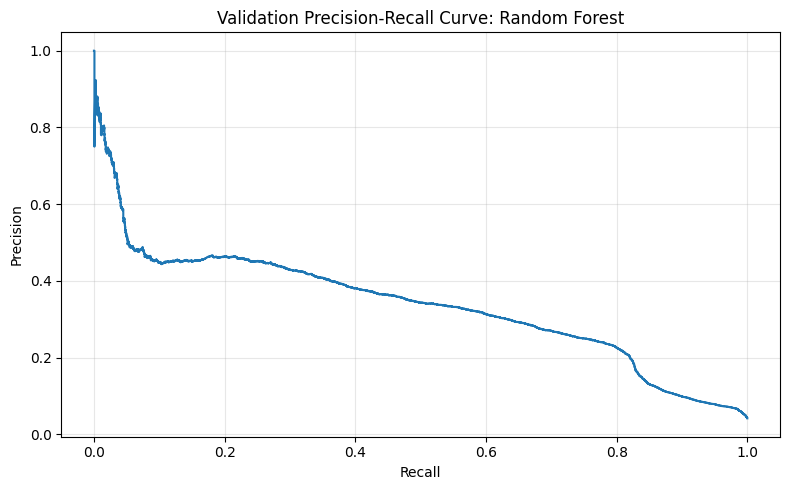

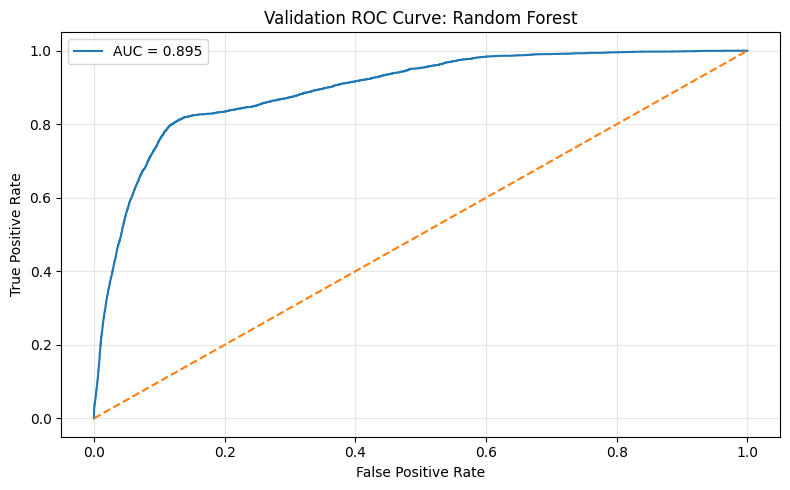

In [20]:
best_val_prob = best_validation_model.predict_proba(X_val)[:, 1]

# Precision-Recall curve
precision, recall, pr_thresholds = precision_recall_curve(
    y_val,
    best_val_prob
)

plt.figure(figsize=(8, 5))
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"Validation Precision-Recall Curve: {best_model_name}")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "validation_precision_recall_curve.png", dpi=160)
plt.show()


# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_val, best_val_prob)
val_roc_auc = roc_auc_score(y_val, best_val_prob)

plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr, label=f"AUC = {val_roc_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"Validation ROC Curve: {best_model_name}")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "validation_roc_curve.png", dpi=160)
plt.show()

## Step 15 — Choose a classification threshold using validation data

For this analysis, I select the validation threshold that maximizes F1 because both false positives and false negatives matter in the screening setting. A real lender could instead choose a cost-sensitive threshold if missing a risky loan were considered more costly.


In [21]:
# precision_recall_curve returns one more precision/recall value than thresholds
p = precision[:-1]
r = recall[:-1]
t = pr_thresholds

f1 = 2 * p * r / (p + r + 1e-12)

best_threshold_index = np.nanargmax(f1)
chosen_threshold = t[best_threshold_index]

print(f"Chosen validation threshold: {chosen_threshold:.3f}")
print(f"Validation precision at threshold: {p[best_threshold_index]:.3f}")
print(f"Validation recall at threshold: {r[best_threshold_index]:.3f}")
print(f"Validation F1 at threshold: {f1[best_threshold_index]:.3f}")

val_pred = (best_val_prob >= chosen_threshold).astype(int)

print("\nValidation confusion matrix:")
print(confusion_matrix(y_val, val_pred))

print("\nValidation classification report:")
print(classification_report(y_val, val_pred, digits=3))

Chosen validation threshold: 0.690
Validation precision at threshold: 0.332
Validation recall at threshold: 0.557
Validation F1 at threshold: 0.416

Validation confusion matrix:
[[87347  4496]
 [ 1776  2234]]

Validation classification report:
              precision    recall  f1-score   support

           0      0.980     0.951     0.965     91843
           1      0.332     0.557     0.416      4010

    accuracy                          0.935     95853
   macro avg      0.656     0.754     0.691     95853
weighted avg      0.953     0.935     0.942     95853



## Step 16 — Optional tuning

The lecture says to tune only after finding a promising model.

This cell is **off by default** because Random Forest tuning on hundreds of thousands of loans can take a while.

If Random Forest is the best validation model, set `RUN_TUNING = True`.

The code uses `TimeSeriesSplit` so the cross-validation folds still respect time order.


In [22]:
RUN_TUNING = False

if RUN_TUNING and best_model_name == "Random Forest":
    from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

    # Sort chronologically before time-based cross-validation
    tune_df = train_model.sort_values("approval_date").copy()

    # Optional runtime control.
    # Use the most recent 150k training observations if the full search is too slow.
    MAX_TUNING_ROWS = 150_000
    if len(tune_df) > MAX_TUNING_ROWS:
        tune_df = tune_df.tail(MAX_TUNING_ROWS)

    X_tune = tune_df[FEATURES]
    y_tune = tune_df[TARGET]

    param_distributions = {
        "model__n_estimators": [100, 150, 200],
        "model__max_depth": [8, 12, 16, None],
        "model__min_samples_leaf": [5, 10, 20, 40],
        "model__max_features": ["sqrt", 0.5, None]
    }

    time_cv = TimeSeriesSplit(n_splits=3)

    search = RandomizedSearchCV(
        estimator=clone(models["Random Forest"]),
        param_distributions=param_distributions,
        n_iter=6,
        scoring="average_precision",
        cv=time_cv,
        n_jobs=-1,
        random_state=RANDOM_STATE,
        verbose=2
    )

    search.fit(X_tune, y_tune)

    print("Best CV PR-AUC:", search.best_score_)
    print("Best parameters:", search.best_params_)

    tuned_model = search.best_estimator_

    tuned_val_prob = tuned_model.predict_proba(X_val)[:, 1]
    tuned_pr_auc = average_precision_score(y_val, tuned_val_prob)

    print("Tuned validation PR-AUC:", tuned_pr_auc)

    # Only replace the original model if tuning really improved validation performance
    original_pr_auc = average_precision_score(y_val, best_val_prob)

    if tuned_pr_auc > original_pr_auc:
        print("Using tuned Random Forest.")
        best_validation_model = tuned_model
        best_val_prob = tuned_val_prob

        precision, recall, pr_thresholds = precision_recall_curve(
            y_val,
            best_val_prob
        )
        p = precision[:-1]
        r = recall[:-1]
        t = pr_thresholds
        f1 = 2 * p * r / (p + r + 1e-12)

        best_threshold_index = np.nanargmax(f1)
        chosen_threshold = t[best_threshold_index]

        print("New chosen threshold:", chosen_threshold)
    else:
        print("Tuning did not improve validation PR-AUC, so keeping the original model.")

elif RUN_TUNING:
    print("Current best model is not Random Forest. No RF tuning was run.")
else:
    print("Tuning skipped. Set RUN_TUNING = True later if needed.")

Tuning skipped. Set RUN_TUNING = True later if needed.


## Step 17 — Generalization and learning curve

The validation table already shows the train-validation PR-AUC gap.

I also make a small learning curve for the selected model. The purpose is not to choose the test result. It is only to see whether adding more training data reduces the gap between training and validation performance.

To keep runtime reasonable on the large SBA file, this diagnostic uses at most 100,000 training rows. The final model later still uses the full development data.


Learning curve values:


,training_rows,Train_PR_AUC,Validation_PR_AUC,Gap
0,25000,0.503148,0.284792,0.218356
1,50000,0.509401,0.297047,0.212354
2,75000,0.487403,0.291336,0.196067
3,100000,0.483604,0.309263,0.174341


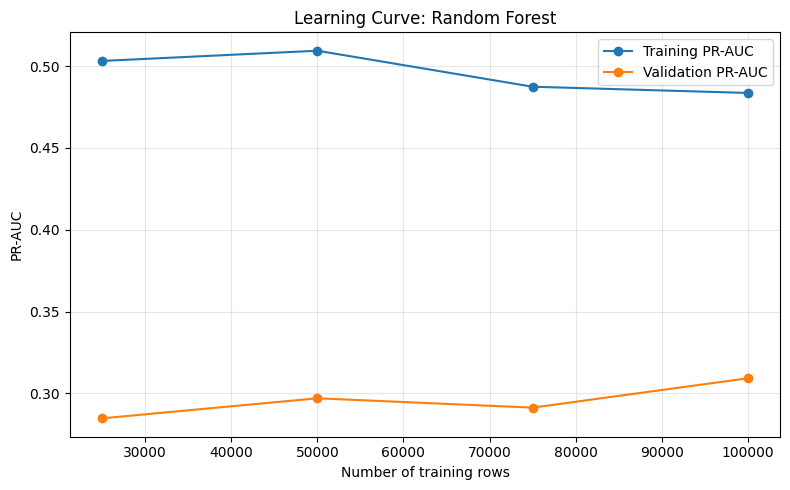


How to read this:
- High training and much lower validation PR-AUC suggests overfitting.
- Low scores on both sets suggest underfitting.
- A smaller gap as training size grows suggests better generalization.


In [23]:
from sklearn.model_selection import train_test_split

# Use only training data for this diagnostic.
# The validation set stays fixed, and the test set is still untouched.
LEARNING_CURVE_MAX_ROWS = 100_000
learning_fractions = [0.25, 0.50, 0.75, 1.00]

lc_pool = train_model.copy()

# If training data are very large, take a stratified sample for this diagnostic only.
if len(lc_pool) > LEARNING_CURVE_MAX_ROWS:
    lc_pool, _ = train_test_split(
        lc_pool,
        train_size=LEARNING_CURVE_MAX_ROWS,
        stratify=lc_pool[TARGET],
        random_state=RANDOM_STATE
    )

learning_rows = []

for frac in learning_fractions:
    if frac < 1.0:
        sample_df, _ = train_test_split(
            lc_pool,
            train_size=frac,
            stratify=lc_pool[TARGET],
            random_state=RANDOM_STATE
        )
    else:
        sample_df = lc_pool.copy()

    lc_model = clone(best_validation_model)

    X_lc = sample_df[FEATURES]
    y_lc = sample_df[TARGET]

    lc_model.fit(X_lc, y_lc)

    train_lc_prob = lc_model.predict_proba(X_lc)[:, 1]
    val_lc_prob = lc_model.predict_proba(X_val)[:, 1]

    learning_rows.append({
        "training_rows": len(sample_df),
        "Train_PR_AUC": average_precision_score(y_lc, train_lc_prob),
        "Validation_PR_AUC": average_precision_score(y_val, val_lc_prob)
    })

learning_curve_df = pd.DataFrame(learning_rows)
learning_curve_df["Gap"] = (
    learning_curve_df["Train_PR_AUC"]
    - learning_curve_df["Validation_PR_AUC"]
)

print("Learning curve values:")
display(learning_curve_df)

plt.figure(figsize=(8, 5))
plt.plot(
    learning_curve_df["training_rows"],
    learning_curve_df["Train_PR_AUC"],
    marker="o",
    label="Training PR-AUC"
)
plt.plot(
    learning_curve_df["training_rows"],
    learning_curve_df["Validation_PR_AUC"],
    marker="o",
    label="Validation PR-AUC"
)
plt.xlabel("Number of training rows")
plt.ylabel("PR-AUC")
plt.title(f"Learning Curve: {best_model_name}")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "learning_curve_pr_auc.png", dpi=160)
plt.show()

learning_curve_df.to_csv(
    OUTPUT_DIR / "learning_curve_pr_auc.csv",
    index=False
)

print("\nHow to read this:")
print("- High training and much lower validation PR-AUC suggests overfitting.")
print("- Low scores on both sets suggest underfitting.")
print("- A smaller gap as training size grows suggests better generalization.")


### Generalization interpretation

The learning curve shows that training PR-AUC remained higher than validation PR-AUC, so some overfitting is still present. However, the gap decreased from about **0.218** with 25,000 training rows to about **0.174** with 100,000 rows.

Validation PR-AUC ended higher overall, increasing from about **0.285** with 25,000 observations to **0.309** with 100,000 observations, although the improvement was **not monotonic at every sample size**. This suggests that additional data can help the model generalize, while the remaining train-validation gap shows that some overfitting remains.


## Step 18 — Validation error analysis

Overall metrics tell me how much error the model makes. This section looks at **which loans** are being misclassified.

I keep the error analysis on validation data so the final test set stays locked.

For this project:

- **False negative:** actual 5-year charge-off, but the model does not flag it
- **False positive:** no 5-year charge-off, but the model flags it

I look at the most confident mistakes first because those are the cases where the model was most wrong.


In [24]:
# Reuse the validation probabilities already created during model/threshold selection.
# If optional tuning improved the model, Step 16 also updates best_val_prob and chosen_threshold.
# Reusing the stored probability vector avoids tiny prediction differences from scoring
# the same Random Forest a second time.
val_pred = (best_val_prob >= chosen_threshold).astype(int)

error_table = val_model.copy()
error_table["actual_chargeoff_5yr"] = y_val.values
error_table["predicted_chargeoff_5yr"] = val_pred
error_table["predicted_probability"] = best_val_prob

error_table["error_type"] = np.select(
    [
        (error_table["actual_chargeoff_5yr"] == 1)
        & (error_table["predicted_chargeoff_5yr"] == 0),

        (error_table["actual_chargeoff_5yr"] == 0)
        & (error_table["predicted_chargeoff_5yr"] == 1)
    ],
    [
        "False Negative",
        "False Positive"
    ],
    default="Correct"
)

validation_errors = error_table[
    error_table["error_type"] != "Correct"
].copy()

print("Validation error counts:")
display(
    validation_errors["error_type"]
    .value_counts()
    .rename("count")
    .to_frame()
)

# Add a few engineered variables that are easier to interpret.
validation_errors = add_features(validation_errors)

error_columns = [
    "error_type",
    "actual_chargeoff_5yr",
    "predicted_chargeoff_5yr",
    "predicted_probability",
    "gross_approval",
    "term_months",
    "initial_interest_rate",
    "guarantee_pct",
    "project_state",
    "naics2",
    "business_age",
    "processing_method"
]

error_columns = [
    c for c in error_columns
    if c in validation_errors.columns
]

# False negatives with the LOWEST predicted probabilities:
# these are risky loans the model felt most confident were low risk.
false_negatives = (
    validation_errors[
        validation_errors["error_type"] == "False Negative"
    ]
    .sort_values("predicted_probability", ascending=True)
)

print("\nMost confident FALSE NEGATIVES:")
display(false_negatives[error_columns].head(10))

# False positives with the HIGHEST predicted probabilities:
# these are performing loans the model felt most confident were high risk.
false_positives = (
    validation_errors[
        validation_errors["error_type"] == "False Positive"
    ]
    .sort_values("predicted_probability", ascending=False)
)

print("\nMost confident FALSE POSITIVES:")
display(false_positives[error_columns].head(10))

# Save the full error table for the report / later review.
validation_errors[error_columns].to_csv(
    OUTPUT_DIR / "validation_error_table.csv",
    index=False
)

# Optional grouped check: which broad industries have more errors?
if "naics2" in validation_errors.columns:
    validation_scored = add_features(val_model.copy())
    validation_scored["actual"] = y_val.values
    validation_scored["predicted"] = val_pred
    validation_scored["is_error"] = (
        validation_scored["actual"]
        != validation_scored["predicted"]
    ).astype(int)

    error_by_industry = (
        validation_scored
        .groupby("naics2")
        .agg(
            loans=("is_error", "size"),
            error_rate=("is_error", "mean")
        )
        .query("loans >= 100")
        .sort_values("error_rate", ascending=False)
    )

    print("\nBroad NAICS sectors with the highest validation error rates")
    print("(only sectors with at least 100 validation loans):")
    display(error_by_industry.head(10))

# Consistency check: the error table must match the validation confusion matrix.
validation_cm = confusion_matrix(y_val, val_pred)

expected_false_positives = int(validation_cm[0, 1])
expected_false_negatives = int(validation_cm[1, 0])

assert len(false_positives) == expected_false_positives, (
    "False-positive count does not match the validation confusion matrix."
)
assert len(false_negatives) == expected_false_negatives, (
    "False-negative count does not match the validation confusion matrix."
)

print("\nError-count consistency check passed.")
print("False positives:", expected_false_positives)
print("False negatives:", expected_false_negatives)


Validation error counts:


,count
error_type,
False Positive,4496
False Negative,1776



Most confident FALSE NEGATIVES:


,error_type,actual_chargeoff_5yr,predicted_chargeoff_5yr,predicted_probability,gross_approval,term_months,initial_interest_rate,guarantee_pct,project_state,naics2,business_age,processing_method
456161,False Negative,1,0,0.137201,1185000.0,144.0,6.5,0.75,KS,62,Change of Ownership,Preferred Lenders Program
496819,False Negative,1,0,0.151841,708300.0,187.0,7.0,0.75,CA,44,Change of Ownership,Preferred Lenders Program
451707,False Negative,1,0,0.161224,2095000.0,254.0,5.9,0.75,CA,44,"Startup, Loan Funds will Open Business",Preferred Lenders Program
536187,False Negative,1,0,0.165794,3750000.0,288.0,7.25,0.75,MI,72,NaN,Preferred Lenders Program
535301,False Negative,1,0,0.166059,1830600.0,138.0,8.0,0.75,FL,62,Change of Ownership,Preferred Lenders Program
478108,False Negative,1,0,0.170513,550000.0,229.0,5.75,0.75,WI,23,Change of Ownership,7a General
539957,False Negative,1,0,0.172762,754000.0,138.0,8.0,0.75,IL,71,NaN,Preferred Lenders Program
548547,False Negative,1,0,0.178686,1080000.0,120.0,7.5,0.75,AL,56,Change of Ownership,Preferred Lenders Program
493639,False Negative,1,0,0.179001,3596000.0,182.0,6.75,0.75,TX,44,Existing or more than 2 years old,Preferred Lenders Program
521069,False Negative,1,0,0.180543,1884000.0,129.0,6.9,0.75,NE,32,Change of Ownership,7a General



Most confident FALSE POSITIVES:


,error_type,actual_chargeoff_5yr,predicted_chargeoff_5yr,predicted_probability,gross_approval,term_months,initial_interest_rate,guarantee_pct,project_state,naics2,business_age,processing_method
544170,False Positive,0,1,0.880645,150000.0,82.0,8.0,0.85,TX,56,"Startup, Loan Funds will Open Business",Preferred Lenders Program
519380,False Positive,0,1,0.876393,150000.0,96.0,8.25,0.85,TX,56,"Startup, Loan Funds will Open Business",Preferred Lenders Program
490627,False Positive,0,1,0.876005,150000.0,79.0,7.75,0.85,TX,81,"Startup, Loan Funds will Open Business",Preferred Lenders Program
501520,False Positive,0,1,0.874213,5000.0,45.0,11.75,0.5,TX,44,NaN,SBA Express Program
539028,False Positive,0,1,0.873182,150000.0,67.0,8.0,0.85,FL,56,"Startup, Loan Funds will Open Business",Preferred Lenders Program
490217,False Positive,0,1,0.872460,150000.0,92.0,7.75,0.85,FL,23,"Startup, Loan Funds will Open Business",Preferred Lenders Program
526588,False Positive,0,1,0.872260,150000.0,64.0,8.25,0.85,FL,56,"Startup, Loan Funds will Open Business",Preferred Lenders Program
536615,False Positive,0,1,0.871324,150000.0,67.0,8.0,0.85,TX,23,"Startup, Loan Funds will Open Business",Preferred Lenders Program
528305,False Positive,0,1,0.868394,150000.0,109.0,8.25,0.85,TX,71,"Startup, Loan Funds will Open Business",Preferred Lenders Program
456391,False Positive,0,1,0.868204,20000.0,57.0,9.5,0.5,CA,21,Existing or more than 2 years old,SBA Express Program



Broad NAICS sectors with the highest validation error rates
(only sectors with at least 100 validation loans):


,loans,error_rate
naics2,,
48,5892,0.089104
42,4331,0.078966
71,3614,0.078860
23,11206,0.077815
61,1584,0.077652
45,3441,0.074397
49,469,0.070362
51,938,0.070362
81,8986,0.069330



Error-count consistency check passed.
False positives: 4496
False negatives: 1776


### Error-analysis interpretation

At the selected validation threshold, the validation confusion matrix shows **4,496 false positives** and **1,776 false negatives**.

The most confident false negatives are not concentrated in only one industry or state. Several are relatively large or long-term loans, and many have a 75% SBA guarantee. This suggests that the public SBA loan characteristics do not capture every source of borrower risk.

The broad-industry error table also shows that model performance is not equally strong across sectors. Among sectors with at least 100 validation loans, NAICS 48, 42, 71, and 23 had some of the highest observed error rates. I treat this as descriptive error analysis, not evidence that industry itself causes charge-off.

This analysis uses validation data only. I do not change the model after seeing the final test results.


# Final evaluation

## Step 19 — Unlock the test set ONCE

At this point:

- feature choices are finished
- model choice is finished
- threshold choice is finished

Now I combine training + validation data, refit the selected pipeline, and evaluate once on the future test period.

Do not go back and change the model just because the test result is lower than expected.


In [25]:
from sklearn.base import clone

# Create features for the test set only now
test_model = add_features(test_df)

# Combine train + validation for the final fit
train_val_model = pd.concat(
    [train_model, val_model],
    ignore_index=True
)

X_train_val = train_val_model[FEATURES]
y_train_val = train_val_model[TARGET]

X_test = test_model[FEATURES]
y_test = test_model[TARGET]

# Clone the selected model structure and refit on all development data
final_model = clone(best_validation_model)
final_model.fit(X_train_val, y_train_val)

# First and only final test prediction
test_prob = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= chosen_threshold).astype(int)

test_metrics = {
    "model": best_model_name,
    "threshold": chosen_threshold,
    "test_PR_AUC": average_precision_score(y_test, test_prob),
    "test_ROC_AUC": roc_auc_score(y_test, test_prob),
    "test_precision": precision_score(y_test, test_pred, zero_division=0),
    "test_recall": recall_score(y_test, test_pred, zero_division=0),
    "test_F1": f1_score(y_test, test_pred, zero_division=0),
    "test_rows": len(y_test),
    "test_chargeoff_rate": y_test.mean()
}

display(pd.DataFrame([test_metrics]))

print("\nTest confusion matrix:")
print(confusion_matrix(y_test, test_pred))

print("\nTest classification report:")
print(classification_report(y_test, test_pred, digits=3))

pd.DataFrame([test_metrics]).to_csv(
    OUTPUT_DIR / "final_test_metrics.csv",
    index=False
)

,model,threshold,test_PR_AUC,test_ROC_AUC,test_precision,test_recall,test_F1,test_rows,test_chargeoff_rate
0,Random Forest,0.689813,0.35245,0.931124,0.425847,0.314063,0.361511,54249,0.023595



Test confusion matrix:
[[52427   542]
 [  878   402]]

Test classification report:
              precision    recall  f1-score   support

           0      0.984     0.990     0.987     52969
           1      0.426     0.314     0.362      1280

    accuracy                          0.974     54249
   macro avg      0.705     0.652     0.674     54249
weighted avg      0.970     0.974     0.972     54249



### Test interpretation

The final Random Forest achieved a **test PR-AUC of 0.352** and a **test ROC-AUC of 0.931** on loans approved from January 2020 through June 2021.

Using the threshold selected from validation data (**0.690**), the model had:

- **Precision:** 0.426
- **Recall:** 0.314
- **F1 score:** 0.362

The test set contained **1,280 actual five-year charge-offs**. The model correctly identified **402** of them and missed **878**. It also flagged **542** loans that did not charge off within five years.

In practical terms, the model identified about **31.4% of actual charge-offs**, while about **42.6% of loans it flagged as high risk actually charged off within five years**.

The test charge-off rate was only **2.36%**, so this is a highly imbalanced prediction problem. The PR-AUC of 0.352 is substantially above the positive-class base rate, which indicates that the model contains useful ranking information even though recall at the selected F1 threshold remains limited.

The test period covers loans originated during the COVID-era lending environment, so differences from the earlier validation period may reflect both model limitations and a shift in the economic environment.

These results show predictive association, not causation. The public SBA data also do not include borrower financial statements, FICO scores, debt-service coverage, liquidity, leverage, or other information that a bank would normally use in underwriting.


## Step 20 — Final confusion matrix plot


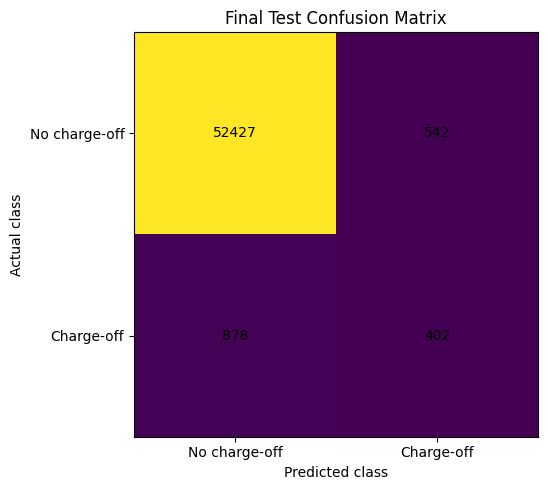

In [26]:
cm = confusion_matrix(y_test, test_pred)

plt.figure(figsize=(6, 5))
plt.imshow(cm)
plt.title("Final Test Confusion Matrix")
plt.xlabel("Predicted class")
plt.ylabel("Actual class")

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.xticks([0, 1], ["No charge-off", "Charge-off"])
plt.yticks([0, 1], ["No charge-off", "Charge-off"])
plt.tight_layout()
plt.savefig(FIGURE_DIR / "final_test_confusion_matrix.png", dpi=160)
plt.show()

## Step 21 — Feature importance / model interpretation

This section depends on which model won.

- Logistic Regression → absolute coefficient size
- Decision Tree / Random Forest → feature importance

Feature importance means the variable was useful for prediction. It does **not** mean the variable caused a charge-off.

### Final feature-importance interpretation

For the fitted Random Forest, **loan term** was by far the largest model importance (about **0.594**). The next largest numeric features were **initial interest rate** (about **0.078**) and **log loan amount** (about **0.076**), followed by **SBA guarantee percentage** (about **0.034**).

This is consistent with the earlier EDA, where shorter-term loans, smaller loans, and higher-rate loans had higher observed five-year charge-off rates.

Random Forest feature importance measures how useful a variable was to this fitted model. It does **not** show that the variable caused charge-off, and the magnitude should not be interpreted as an economic causal effect.


,feature,importance
2,num__term_months,0.593696
3,num__initial_interest_rate,0.077775
0,num__log_gross_approval,0.076144
1,num__guarantee_pct,0.033771
104,cat__collateral_ind_N,0.019355
5,num__approval_year,0.017126
105,cat__collateral_ind_Y,0.015975
95,cat__processing_method_SBA Express Program,0.015501
68,"cat__business_age_Existing, 5 or more years",0.011495
4,num__jobs_supported,0.010977


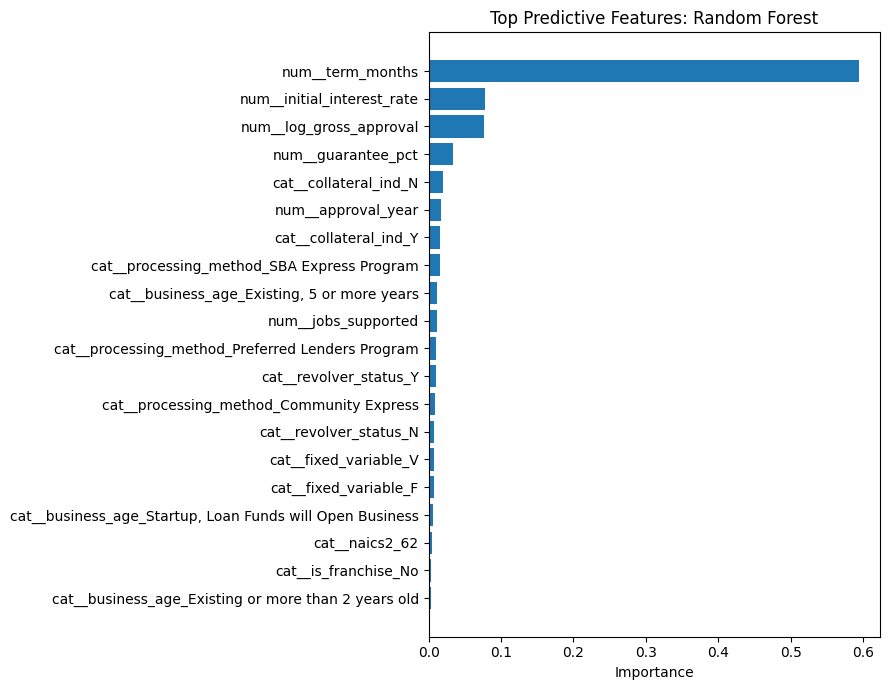

In [27]:
fitted_preprocessor = final_model.named_steps["preprocessor"]
fitted_estimator = final_model.named_steps["model"]

feature_names = fitted_preprocessor.get_feature_names_out()

importance_df = None

if hasattr(fitted_estimator, "feature_importances_"):
    importance_df = pd.DataFrame({
        "feature": feature_names,
        "importance": fitted_estimator.feature_importances_
    })

elif hasattr(fitted_estimator, "coef_"):
    importance_df = pd.DataFrame({
        "feature": feature_names,
        "importance": np.abs(fitted_estimator.coef_[0]),
        "signed_coefficient": fitted_estimator.coef_[0]
    })

if importance_df is not None:
    importance_df = importance_df.sort_values(
        "importance",
        ascending=False
    )

    display(importance_df.head(20))

    importance_df.to_csv(
        OUTPUT_DIR / "feature_importance.csv",
        index=False
    )

    top = importance_df.head(20).sort_values("importance")

    plt.figure(figsize=(9, 7))
    plt.barh(top["feature"], top["importance"])
    plt.xlabel("Importance")
    plt.title(f"Top Predictive Features: {best_model_name}")
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / "top_feature_importance.png", dpi=160)
    plt.show()

else:
    print("This model does not expose simple feature importance.")

## Step 22 — Save the complete fitted pipeline

Saving the pipeline keeps both preprocessing and the model together.


In [28]:
import joblib

model_path = OUTPUT_DIR / "sba_chargeoff_5yr_pipeline.joblib"
joblib.dump(final_model, model_path)

print("Saved final pipeline to:")
print(model_path)

print("\nGenerated project outputs:")
for path in sorted(OUTPUT_DIR.glob("*")):
    print("-", path.name)

print("\nGenerated figures:")
for path in sorted(FIGURE_DIR.glob("*")):
    print("-", path.name)

Saved final pipeline to:
/Users/chloepham/Downloads/DATA400_SBA_Credit_Risk/output/sba_chargeoff_5yr_pipeline.joblib

Generated project outputs:
- feature_importance.csv
- final_test_metrics.csv
- learning_curve_pr_auc.csv
- sba_chargeoff_5yr_pipeline.joblib
- validation_error_table.csv
- validation_model_comparison.csv

Generated figures:
- chargeoff_by_loan_amount_band.png
- chargeoff_rate_by_year.png
- final_test_confusion_matrix.png
- learning_curve_pr_auc.png
- loan_amount_distribution.png
- numeric_target_correlations.png
- top_feature_importance.png
- validation_precision_recall_curve.png
- validation_roc_curve.png


# Final results summary

## Data

- Raw loans after exact-duplicate removal: **932,013**
- Loans with a complete five-year window and usable target: **543,110**
- Loans excluded because charge-off evidence existed but exact timing was unavailable: **15**
- Overall five-year charge-off rate in the modeling universe: **3.76%**
- Latest eligible approval date: **June 30, 2021**
- Data-quality check: **208 training loans (about 0.05%) had non-positive loan terms**; these were flagged as a limitation rather than removed after model development.

### Time split

- **Training:** 393,008 loans; October 1, 2009–December 31, 2017; charge-off rate **3.86%**
- **Validation:** 95,853 loans; 2018–2019; charge-off rate **4.18%**
- **Test:** 54,249 loans; January 2020–June 2021; charge-off rate **2.36%**

The October 2009 training start occurs because the SBA FY2010 source contains fiscal-year 2010 approvals beginning in October 2009.

## Main EDA findings

- Smaller loans had higher observed five-year charge-off rates. Loans below $50,000 had a rate of about **5.59%**, compared with about **0.85%** for loans above $1 million.
- Shorter-term loans had higher observed charge-off rates. Loans with terms of 84 months or less had a rate of about **5.11%**, compared with about **0.48%** for terms above 180 months.
- Higher-rate loans showed higher observed charge-off rates. The 8–11% interest-rate band had a rate of about **7.30%**, compared with about **1.35%** for rates below 5%.
- Charge-off rates also varied across broad NAICS sectors and SBA guarantee bands.

These are descriptive relationships, not causal effects.

## Model selection

Validation PR-AUC:

- Dummy: **0.042**
- Logistic Regression: **0.159**
- Decision Tree: **0.252**
- Random Forest: **0.337**

Random Forest was selected because PR-AUC was the predefined primary metric.

### Validation threshold

Selected threshold: **0.690**

- Precision: **0.332**
- Recall: **0.557**
- F1: **0.416**

Validation confusion matrix:

- True negatives: **87,347**
- False positives: **4,496**
- False negatives: **1,776**
- True positives: **2,234**

## Generalization

The Random Forest showed some overfitting. In the learning-curve diagnostic, the train-validation PR-AUC gap decreased from about **0.218** to **0.174** as the training sample increased from 25,000 to 100,000 rows. Validation PR-AUC ended higher overall (**0.285 → 0.309**), although it did not improve monotonically at every sample size. This suggests that additional data can help, but a generalization gap remains.

## Final locked test

Random Forest, threshold 0.690:

- Test PR-AUC: **0.352**
- Test ROC-AUC: **0.931**
- Precision: **0.426**
- Recall: **0.314**
- F1: **0.362**
- Test rows: **54,249**
- Test charge-off rate: **2.36%**

Final confusion matrix:

- True negatives: **52,427**
- False positives: **542**
- False negatives: **878**
- True positives: **402**

## Most predictive features

The Random Forest's largest feature importance was loan term (**0.594**), followed by initial interest rate (**0.078**), log loan amount (**0.076**), and SBA guarantee percentage (**0.034**).

These values describe the fitted model and should not be interpreted as causal effects.

## Main limitations

- The public SBA data do not contain the full borrower financial information used in real commercial underwriting, such as cash flow, DSCR, leverage, liquidity, credit history, or management quality.
- Loans approved after June 30, 2021 are excluded because they do not yet have a complete five-year observation window in the June 30, 2026 snapshot.
- The final test period contains COVID-era originations and may represent a different economic environment from the training period.
- Charge-off is an observable credit outcome but is not identical to every definition of default or financial distress.
- The sample contains approved SBA 7(a) loans, so the results should not automatically be generalized to all commercial borrowers.
- The analysis is predictive rather than causal.
- The F1-based threshold is an analytical decision rule, not an economically optimized underwriting cutoff.
